## Урок 3

### Урок 3.1. Когда использовать `raise`, а когда `return`

Оба способа позволяют функции сообщить вызывающему коду о результате, но предназначены для разных ситуаций

Если рассматривать пример `Process Runner` из предыдущего урока, то это будет:

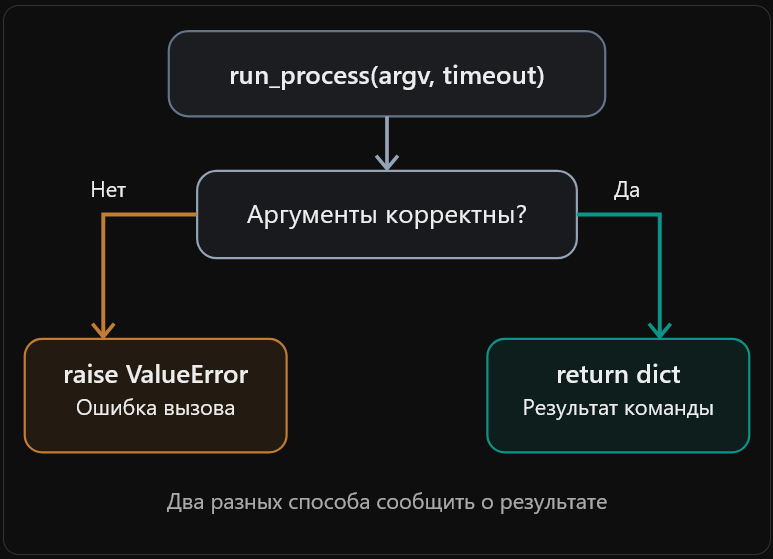

**Ситуация 1. Некорректно вызвали функцию

``` python
run_process([], 5)
```

Пустая команда нарушает контракт функции

``` python
raise ValueError("Передан пустой список команд")
```

Это ошибка нашего программного кода или вызывающей стороны. Ее нужно исправить


**Ситуация 2. Команда выполнилась, но завершилась неуспешно**

Например:

``` python
run_process(
    [sys.executable, "-c", "import sys; sys.exit(7)"],
    5
)
```

Здесь вызов функции корректен. Процесс успешно запущен, получен его результат - он завершился с кодом `7`

По нашему контракту функция должна вернуть:

``` python
{
    "status": "failed",
    "returncode": 7,
    "stdout": "",
    "stderr": ""
}
```

То есть **неуспешное дочерней команды не обязательно означает ошибку самого Process Runner**

В других приложениях можно выбрать иную архитектуру, но для нашего учебного Harness мы договорились возвращать результат команды словарем


**Где нужно обрабатывать исключения?**

Это следующий важный момент

Предположим, что вызываем `run_process()` из другой функции

``` python
def execute_command():
    result = run_process([], 5)
    print(result)
```

При таком вызове возникнет `ValueError`, который распространится из `run_process()` в `execute_command()`

Но мы можем перехватить его на уровне вызывающей функции:

``` python
def execute_command():
    try:
        result = run_process([], 5)
        print(result)

    except ValueError as e:
        print(f"Ошибка аргументов: {e}")
```

Так мы разделяем обязанности:

- `run_process()` проверяет аргументы и выполняет команду
- `execute_command()` решает, как реагировать на ошибку вызова

В большом приложении такое разделение очень полезно: исполнитель не должен самостоятельно решать, как пользователю показывать все ошибки



### Урок 3.2. `try/except/else/finally`

До этого момента использовались только две конструкции:

``` python
try:
    # выполнить операцию
except ValueError:
    # обработать ошибку
```

Но у `try` есть еще два необязательных блока: `else` и `finally`

Рассмотрим пример:

``` python
try:
    number = int("25")

except ValueError:
    print("Ошибка преобразования")

else:
    print("Преобразование прошло успешно")

finally:
    print("Операция завершена")
```

Результат:

``` text
Преобразование прошло успешно
Операция завершена
```

Почему?

`else` выполняется, если блок `try` завершился без исключения

`finally` выполняется при выходе из конструкции `try`, независимо от того, было исключение или нет. Он выполнится даже перед распространением необработанного исключения


**Как устроен процесс**

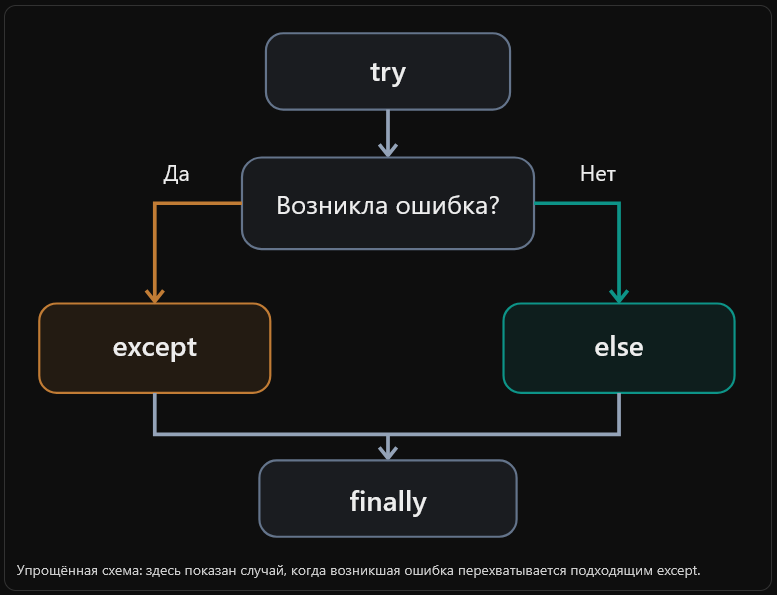

Сравним поведение:

| Ситуация              | `except` | `else` | `finally`                         |
|-----------------------|----------|--------|-----------------------------------|
| Ошибки нет            | Нет      | Да     | Да                                |
| Ошибка перехвачена    | Да       | Нет    | Да                                |
| Ошибка не перехвачена | Нет      | Нет    | Да, перед распространением ошибки |


**Зачем нужен `finally`?**

Представим, что Harness создает временный файл, запускает команду и затем должен этот файл удалить

Даже если команда завершилась с ошибкой, временный файл желательно убрать

Для подобных операций и используют `finally`: освобождение ресурсов, закрытие соединений, удаление временных файлов и другие действия, которые нужно выполнить независимо от результата


